### Linear Regression analysis

SOME NICE INTRODUCTION HERE - LINK TO OTHER TEXT
Intuitively, an animal with a shorter lifespan is subject to more danger due to predation, and environmental factors including the exposure of their habitat to factors limiting their lifespan. We assume that this could have some impact on the amount that the animal sleeps each night (so an animal that is in more danger and is more exposed will sleep less, and is also more likely to have a shorter lifespan). 

We would like to test these assumptions through multiple methods. This following section of the notebook will evaluate the relationship between the **lifespan of an animal and the total duration that the animal sleeps on average each night**. In this case, the dependent variable is the maximum lifespan, and the independent variable used to predict is the total duration of sleep.

In order to examine this relationship, we have chosen to use linear regression techniques from the package Scikit learn to train a model and discuss how accurately it can predict the maximum lifespan using diagnostic methods. 

Finally, we will test the null hypothesis that there is no relationship between an animal's lifespan and the average duration that it sleeps per day on a confidence interval of 5%, using the previously trained and cross validated model.

#### Linear regression - cross validation and diagnostics

Firstly, we will train a linear regression model on training data using a 70/30 split of training and test data. This split was chosen based on the size of the dataset in total. As demonstrated in the code cells below, once all invalid inputs are removed from the dataset, one is left with 54 entries (quite small for running analysis on). 70/30 is a split that both allows the model to be trained on sufficient data while also providing enough for a reasonable test.

Since the dataset this model is trained on is quite small (only 37 datapoints), the k fold value **k = 2** was chosen to ensure that there is enough data in each train split to obtain a model that is as representative of the data as possible. 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import ShuffleSplit
from sklearn.model_selection import KFold
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn import linear_model
from sklearn.linear_model import LinearRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.multiclass import OneVsOneClassifier
from sklearn.metrics import ConfusionMatrixDisplay

from sklearn.metrics import mean_squared_error, r2_score

import statsmodels.api as sm
import seaborn as sns

from scipy import stats

In [2]:
data = pd.read_csv("dataset_2191_sleep.csv")
#clean data: drop question mark values
data = data[(data['max_life_span'] != '?') & (data['total_sleep'] != '?')]

#max_life_span and total_sleep are string values originally - convert these to floats!
data["max_life_span"] = data["max_life_span"].astype(float)
data["total_sleep"] = data["total_sleep"].astype(float)
data.info()

<class 'pandas.DataFrame'>
Index: 54 entries, 0 to 60
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   body_weight           54 non-null     float64
 1   brain_weight          54 non-null     float64
 2   max_life_span         54 non-null     float64
 3   gestation_time        54 non-null     str    
 4   predation_index       54 non-null     int64  
 5   sleep_exposure_index  54 non-null     int64  
 6   danger_index          54 non-null     int64  
 7   total_sleep           54 non-null     float64
dtypes: float64(4), int64(3), str(1)
memory usage: 3.8 KB


In [3]:
#define dependent and independent variables for later use
max_life_span = data["max_life_span"] #dependent
sleep_time = data["total_sleep"] #independent variable

#convert these to numpy arrays - necessary for the models later
max_life_span = max_life_span.to_numpy()
sleep_time = sleep_time.to_numpy()

#reshaping models to have correct dimensions for the analysis later
sleep_time = sleep_time.reshape(-1, 1)
max_life_span = max_life_span.reshape(-1, 1)

In [4]:
#split data into 70% training, and 30% test
X_train, X_test, y_train, y_test = train_test_split(sleep_time, max_life_span, test_size=0.3, random_state=42)
#since the original variables sleep_time and max_life span are already numpy arrays, these variables are already numpy arrays so we forgo converting them again

#adjust dimensions of splits
X_test = X_test.reshape(-1, 1)
X_train = X_train.reshape(-1, 1)
y_train = y_train.reshape(-1, 1)

In [5]:
# Make sure dependent variables are 1D
y_train = y_train.ravel()
y_test = y_test.ravel()

In [6]:
#since X_train is small -> chose k = 2 so that each time the model runs there is at least some meaningful amount of data
k = 2
kf = KFold(n_splits=k,shuffle=True,random_state=42)

In [7]:
#train model 
mse_ols_results = []


for (train, val) in kf.split(X_train):
    x_t, y_t = X_train[train], y_train[train]
    x_v, y_v = X_train[val], y_train[val]
    
    model1 = LinearRegression()
    model1.fit(x_t, y_t)

    # Predict on the validation observations
    predictions = model1.predict(x_v)
    
    # Calculate validation MSE
    mse = mean_squared_error(y_v, predictions)

    mse_ols_results.append(mse)

print(f"MSE from each fold: {mse_ols_results}")

MSE from each fold: [481.85459458123154, 200.68479859976387]


Running the cross validation on each fold, we obtain two values for the Mean Squared Error (481.8 and 200.7). Especially noteworthy here is that they differ quite significantly between the two folds. This could be due to the small sample size, since even with randomly splitting X_train into two there is a lot of potential for extremely influential points.

To evaluate the model as a whole, the average below is provided. It states that the average MSE for this model is 341.3, which corresponds to a RMSE of about 18.5 years. This is a very large error for measurements of lifespan, so this model should be approached with a lot of caution for making actual predictions. 

In [8]:
#average MSE from this model
avg_mse = sum(mse_ols_results)/len(mse_ols_results)
print(avg_mse)

341.2696965904977


As a next step, the model will be tested using the remaining 30% test data. 

In [9]:
#test model
model1 = model1.fit(X_train, y_train)

y_predicted = model1.predict(X_test)
#return the MSE based on the test data
test_mse = mean_squared_error(y_test, y_predicted)
print(test_mse)

289.7018706576074


The MSE for the model ran on the test data is much lower than the average MSE for the trained model. This is again possibly due to the very small sample size of this dataset, which allows for more fluctuations in the measurements of averages. The RMSE for this tested model is 17.02, so while the deviation is slightly less than the RMSE of the trained model, it is still a very large error for predicting the maximum lifespan. 

As a next step, the slope and intercept of this model will be extracted, in order to plot the training data and the trendine it predicts. This will also be necessary at later points in the code. 

In [11]:
#obtain slope and intercepts of this model
slope = model1.coef_[0]
intercept = model1.intercept_

print(slope)
print(intercept)

-1.5265678243751688
34.33764594769425


R squared value for this model:0.14


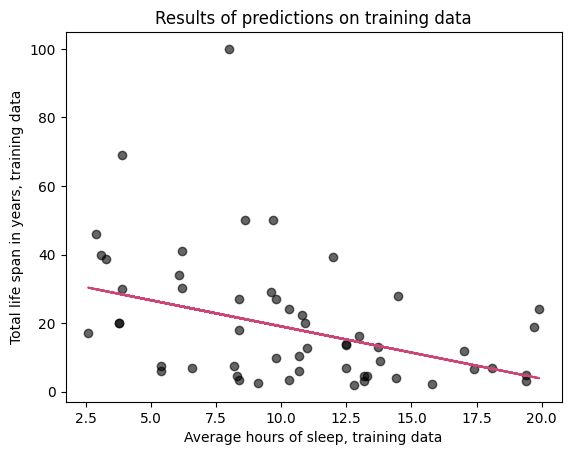

In [23]:
y = model1.predict(X_train)

plt.scatter(sleep_time, max_life_span, c = 'k', alpha = 0.6)
plt.plot(X_train, y, c= '#cc4778')
plt.xlabel("Average hours of sleep, training data")
plt.ylabel("Total life span in years, training data")
plt.title("Results of predictions on training data")

print(f"R squared value for this model:{r2_score(y_train, y):.2f}")

This plot above shows the distribution of the dependent variables of total life span in the training data. In general, there is a somewhat negative trend between the two variables. This means that for every extra hour that an animal sleeps, this model predicts that their overall lifespan decreases. This is counterintutitive and does not confirm our initial assumptions above. 

For reference, the predicted lifespans are also plotted, based on the training data. It does follow the general negative trend, but there is still quite a lot of spread of datapoints above and below the predicted values. This also follows from the $R^2$ value for this model, which is very low at $R^2 = 0.14$. This already indicates that the linear model is not a particularly good fit for the data.

##### Comparison of predicted and actual values of training data:

While it has already been established that the model is not very good at predicting the training data, the plot below is also included to more accurately show the difference between the predicted and actual inputs for the dependent variable max life span. As is also clear from this plot, the model does not do an accurate job of predicting, since only very few datapoints fall on the reference line (which acts as a stand in for the model predicting with 100% accuracy).

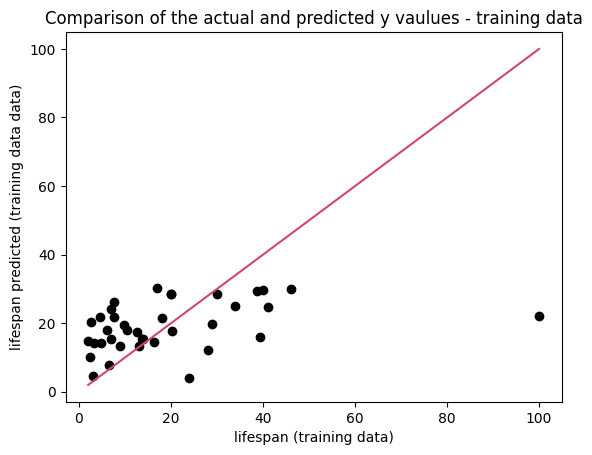

In [29]:
plt.scatter(y_train, y, c = 'k', alpha = 0.7)
plt.title("Comparison of the actual and predicted y vaulues - training data")
plt.xlabel("lifespan (training data)")
plt.ylabel("lifespan predicted (training data data)")
plt.plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], color='#cc4778') #reference line


##### Comparisons for test data: 

This process can be repeated using y_predicted (predicted values based on test data) in order to visualize how accurately the maximum lifespan is predicted using the test data. 

The resulting plot shows that the model performs even worse than on the training data, with only two datapoints being predicted accurately. This is again possibly due to the very small size of the dataset.

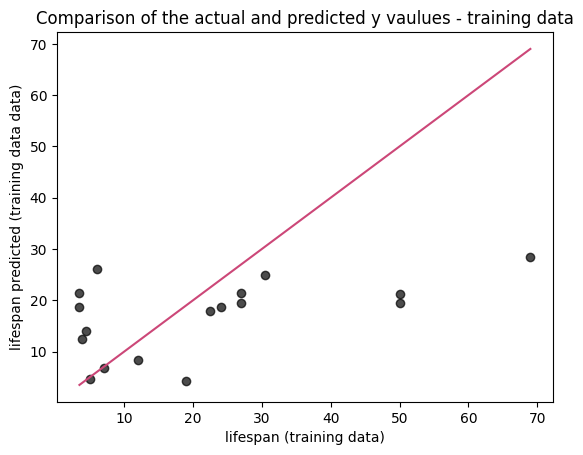

In [32]:
plt.scatter(y_test, y_predicted, c = 'k', alpha = 0.7)
plt.title("Comparison of the actual and predicted y vaulues - training data")
plt.xlabel("lifespan (training data)")
plt.ylabel("lifespan predicted (training data data)")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='#cc4778') #reference line


#### Diagnostics on linear model

The above plots have established that the model is not a good fit for the data that is given. However, to be more accurate, the following section includes diagnostic tests on the training data. Since the test dataset is so small, the diagnostics on that have been omitted, since they are too small to be represetative of the dataset as a whole. 

In [52]:
def least_squares_diagnostics_train(X_train,y_train):
    #residuals, leveraegs, and standard residuals are calucated here, since model is not made using stats package, the functions do not work
    
    #model is fitted on training data!
    model1.fit(X_train, y_train)

    #ideal y values
    y_predicted = model1.predict(X_train)
    train_mse = mean_squared_error(y_train, y_predicted)
    
    #residuals
    residuals = y_train - y_predicted
    
    # calculate leverages
    H = X_train @ np.linalg.pinv(X_train.T @ X_train) @ X_train.T
    h_ii = np.diag(H) #leverages
    
    #calculate the standard residuals
    s_i = residuals / np.sqrt(train_mse * (1- h_ii)) #standard residuals
    
    #calculate cook's distance
    n = X_train.shape[0]
    p = X_train.shape[1]
    dof = n-p
    cook_distance = (s_i ** 2/p) * h_ii/(1-h_ii)

    h_grid = np.linspace(np.min(h_ii),np.max(h_ii),100)
    
    l_thr = 2*p/n # leverage threshold
    d_thr = 4.0 /dof # cook's distance threshold
    s_cook = np.sqrt(d_thr * p * (1-h_grid) / h_grid)

    
#plotting
    fig, ax = plt.subplots(4,1,sharex=False,sharey=False, figsize=(6,15))

    plt.suptitle('Least squares diagnostics - on training data')
    # residual plot
    #ADD THE HORIZONTAL BAR
    ax[0].set_title('Residuals')
    ax[0].scatter(y, residuals, alpha =0.7, color = 'black', label = "Residuals")
    ax[0].hlines(0,np.min(y),np.max(y),linewidth=2, color = '#cc4778', label = "Reference line")
    ax[0].set_xlabel('maximum lifespan')
    ax[0].set_ylabel('Residuals')
    ax[0].legend()

    # q-q plot
    osm, osr = stats.probplot(s_i,dist='t',fit=False,sparams=(n-p-1))
    ax[2].set_title('Q-Q')
    ax[2].scatter(osm,osr, color = 'black', alpha =0.7, label = "Standard residuals")
    ax[2].plot(osm,osm, linewidth = 2, color = '#cc4778', label = "Reference line")
    ax[2].set_xlabel('Theoretical quantile')
    ax[2].set_ylabel('Real quantile')
    ax[2].legend()
    
    # scale-location plot
    ax[1].set_title('Scale-location')
    ax[1].scatter(y_predicted,np.sqrt(abs(s_i)), color = 'black', alpha =0.7)
    ax[1].set_xlabel('Predicted values')
    ax[1].set_ylabel('|Std. Res.|$^{1/2}$')
    
    # residuals vs leverage plot
    ax[3].set_title('Residuals vs leverage')
    ax[3].scatter(h_ii,s_i, alpha =0.7, color = 'black')
    if( np.min(s_cook) < np.max(s_i) or np.max(-s_cook) > np.min(s_i) ):
        plt.plot(h_grid,s_cook, color = '#cc4778', linewidth = 1, label = "Cook's distance")
        plt.plot(h_grid,-s_cook, color = '#cc4778', linewidth = 1)
    if( l_thr < 1.1 * np.max(h_ii) ):
        plt.vlines(l_thr,np.min(s_i),np.max(s_i), color = '#f2844b', linewidth = 1, label = "leverage threshold")
    if( np.max(s_i) > 2.5 or np.min(s_i) < -2.5 ):
        plt.hlines([-3,3],np.min(h_ii),np.max(h_ii),color = '#f2844b', linewidth = 1)
    ax[3].set_xlabel('Leverage')
    ax[3].set_ylabel('Std. Res.')
    ax[3].legend()

    
    plt.tight_layout()
    plt.show()

    return

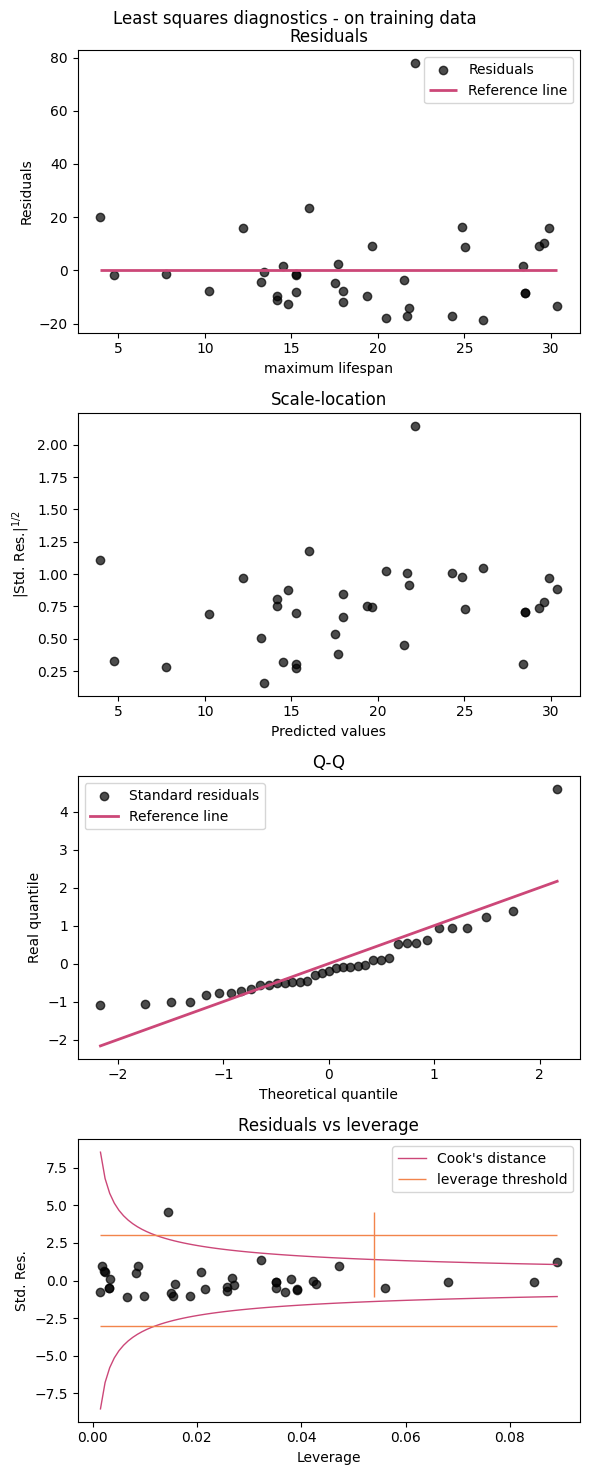

In [53]:
least_squares_diagnostics_train(X_train, y_train)

The results of each plot indicates the following: 

1. **Maximum lifespan vs. Residuals:** This plot gives an indication of how the residuals for each dependent variable are distributed with respect to the reference line representing the ideal situation in which all residuals are equal to 0 (so no deviation). From this plot one can tell that the residuals are not uniformly distributed and that there tend to be more values that fall below the reference line (so more negative residuals). This means that the model consistently underestimates the true depedent value for most of the datapoints. This lack of a uniform spread is also the first indication that the data is not homoscedastic.
   
2. **Scale - location plot:** The scale location plot gives us a more definitive result as to the hetereo- or homoscedasticity of the data. In this case, one can see that there is no real order to the data, and that it is quite scattered across all possible values for the true data, meaning that it is not uniform. The data therefore is heteroscedastic.

   
3. **Q-Q plot:** In this case, the data is evaluated to see how normally distributed it is. The real quantiles follow a sort of linear path, but are not arranged along the predictions made for the theoretical quantiles. There is therefore quite a lot of scattering both above and below what the theoretical quantiles predict, which indicates that the data is not normally distributed. Since this pattern is consistent among all quantiles, it can be concluded that no part of the data is normally distributed.

   
4. **Residuals vs. leverage plot:** This plot shows the number of points that are particularly influential for the model. By plotting Cook's distance (in pink) and the leverage thresholds in orange, the datapoints that fall outside of these boundaries are considered especially influential. For the training data, this is only five points in total. However, since the dataset is very small, these few points can have a very significant impact for the overall predictive abilities of the model.


In conclusion, the diagnostic test on the training data shows that the linear regression model that was trained could be improved upon greatly to accurately predict the outcomes of the dataset. This is due to the fact that the data is neither homoscedastic, nor is it uniformly distributed. The small number of influential points that exist are also likely skewing the predictive abilities of the model because of the dataset's very small sample size. 

#### Hypothesis testing on cross validated linear model

Finally, the model will be evaulated using hypothesis testing. In this case, the null hypothesis is that there is no relation between the two variables, and the alternative hypothesis is that there is some sort of linear relationship. In terms of the regression coeffcieints, this is:

- H$_0$: the slope of the linear regression is zero ($\beta_1=0$). (no linear relation)
- H$_1$: the slope of the linear regression is not zero ($\beta_1\neq0$). (linear relation)

We use a two-sided test with a significance threshold of 0.05.

In [54]:
results = model1.predict(X_train)
#recall: slope is the coefficient of the model fitted on the training data

#all of this below is to accurately calculate the p values!

residuals = y_train - results

n = len(y_train)
p = X_train.shape[1]

dof = n - p - 1

variance_residuals = np.sum(residuals**2)/dof

X = np.column_stack((np.ones(n), X_train))

cov_matrix = variance_residuals * np.linalg.inv(X.T @ X)
standard_errors = np.sqrt(np.diag(cov_matrix))

t_value = float(np.asarray(slope).squeeze() / standard_errors[1])

p_value = 2 * stats.t.sf(abs(t_value), dof)

print(f'P-value: {p_value}')
alpha = 0.05
#p_values = results.pvalue
if p_value < alpha:
    print("Reject the null hypothesis.")
else:
    print("Fail to reject the null hypothesis.")

P-value: 0.02095450646223376
Reject the null hypothesis.


Running the two sided hypothesis test on the model trained above gives us a p - value of approximately 0.021. This falls underneath the determined threshold of 5%, giving a first indication that the null hypothesis should be rejected. This means that there is some sort of linear relationship between the two variables. 

While this does somewhat contradict the results of the diagnostics on the model, this indicates that perhaps the specific regression model used is at fault, since there could still be some sort of linear relationship between the variables, but that the model trained above was not robust enough to accurately predict this.

##### Bootstrapping

In [26]:
def linear_regression(X, y):
    X = np.asarray(X).reshape(-1, 1)
    y = np.asarray(y).ravel()
    model = LinearRegression()
    results = model.fit(X, y)
    return results.coef_[0], results.intercept_

a, b = linear_regression(X_train, y_train)

res = stats.bootstrap((np.asarray(X_train).ravel(),np.asarray(y_train).ravel()), linear_regression, confidence_level=0.95, paired=True, vectorized=False, random_state=42, axis = 0)

conf_int = res.confidence_interval
low = conf_int.low
high = conf_int.high

print("slope:     ", a, "[", low[0], ",", high[0], "]")
print("intercept: ", b, "[", low[1], ",", high[1], "]")
print("p-value:   ", p_value)

slope:      -1.5265678243751688 [ -2.439677171164744 , -0.5275304253203321 ]
intercept:  34.33764594769425 [ 22.793056937500342 , 49.383534320217336 ]
p-value:    0.028335415320787646


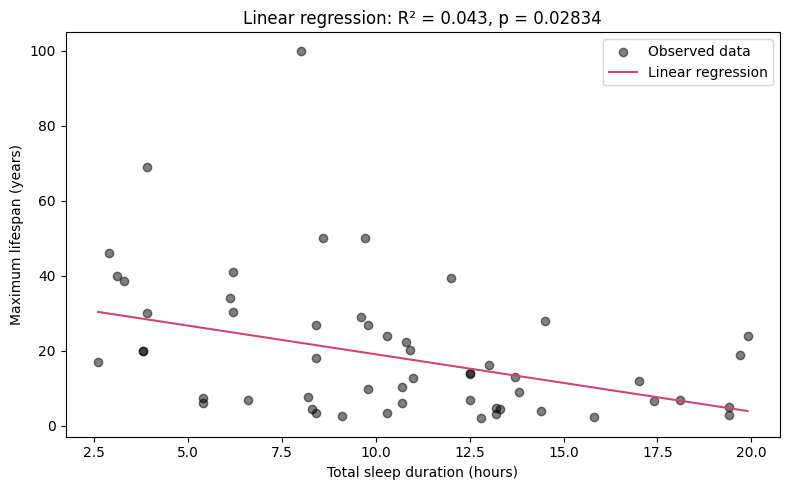

In [22]:
x_line = np.linspace(min(sleep_time), max(sleep_time), 100)
y_line = a * x_line + b

y_predicted = model1.predict(X_train)
plt.figure(figsize=(8, 5))
plt.scatter(sleep_time, max_life_span, c='k', label='Observed data', alpha = 0.5)
plt.plot(x_line, y_line, color='#cc4778', label='Linear regression')
plt.xlabel('Total sleep duration (hours)')
plt.ylabel('Maximum lifespan (years)')
plt.title(f'Linear regression: R² = {r2_score(y_train, y_predicted):.3f}, p = {p_value:.4g}')
plt.legend()
plt.tight_layout()
plt.show()

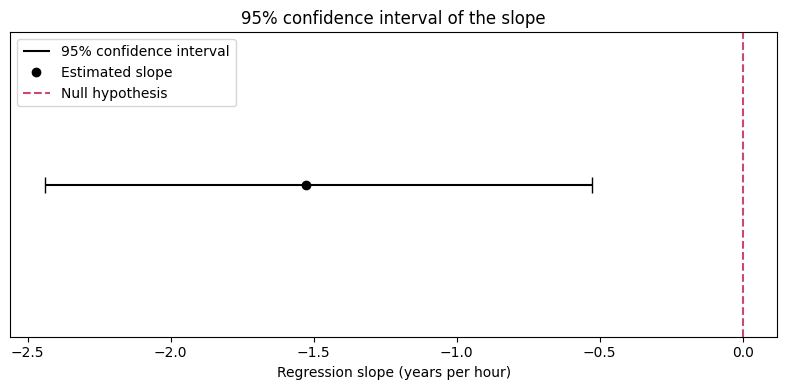

In [23]:
plt.figure(figsize=(8, 4))
plt.hlines(0, low[0], high[0], color='black', label='95% confidence interval')
plt.plot([low[0], high[0]], [0, 0], '|', color='black', markersize=12)
plt.plot(a, 0, 'ko', label='Estimated slope')
plt.axvline(0, color = '#cc4778', linestyle='--', label='Null hypothesis')
plt.xlabel('Regression slope (years per hour)')
plt.title('95% confidence interval of the slope')
plt.yticks([])
plt.legend()
plt.tight_layout()
plt.show()

##### Drawing conclusions

A p-value below 0.05 provides evidence against the null hypothesis. If the bootstrap confidence interval excludes zero, it also supports a nonzero slope. The two methods need not always agree.

The slope describes the estimated change in maximum lifespan per additional hour of sleep. This is an association, not evidence of causation. The conventional slope test assumes independent observations, a linear mean relationship, constant residual variance and approximately normal errors. Shared evolutionary ancestry and omitted variables such as body mass may limit interpretation. This analysis uses all cleaned observations and is exploratory if the hypothesis was formulated after inspecting the data.

In [24]:
print(f"Slope: {a:.4f} years per hour")
print(f"95% bootstrap CI: [{low[0]:.4f}, {high[0]:.4f}]")
print(f"p-value: {p_value:.6g}")
if p_value < alpha:
    direction = 'negative' if a < 0 else 'positive'
    print(f"There is statistically significant evidence of a {direction} linear relationship.")
else:
    print("There is insufficient evidence of a nonzero linear slope.")

Slope: -1.5266 years per hour
95% bootstrap CI: [-2.4397, -0.5275]
p-value: 0.0283354
There is statistically significant evidence of a negative linear relationship.


### Summary of results

### Limitations and Discussion